In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"C:\Users\bhatk\Downloads\archive (2)\Housing_Price_Data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display first five rows
print("First five rows:")
display(df.head())

# Display last five rows
print("\nLast five rows:")
display(df.tail())

# Dataset dimensions
print("\nDataset shape:", df.shape)

# Column information
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
display(df.describe())

# Column names
print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Last five rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished



Dataset shape: (545, 13)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Statistical summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nData cleaning completed!")

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate records: 0

Missing values after cleaning:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Data cleaning completed!


In [5]:
# Create a copy for preprocessing
processed_df = df.copy()

# Convert yes/no columns into 1/0
binary_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

for col in binary_columns:
    processed_df[col] = processed_df[col].map({
        'yes': 1,
        'no': 0
    })

# One-hot encode furnishing status
processed_df = pd.get_dummies(
    processed_df,
    columns=['furnishingstatus'],
    dtype=int
)

print("Preprocessing completed!")
display(processed_df.head())

print("\nProcessed dataset information:")
processed_df.info()

Preprocessing completed!


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0,0



Processed dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   price                            545 non-null    int64
 1   area                             545 non-null    int64
 2   bedrooms                         545 non-null    int64
 3   bathrooms                        545 non-null    int64
 4   stories                          545 non-null    int64
 5   mainroad                         545 non-null    int64
 6   guestroom                        545 non-null    int64
 7   basement                         545 non-null    int64
 8   hotwaterheating                  545 non-null    int64
 9   airconditioning                  545 non-null    int64
 10  parking                          545 non-null    int64
 11  prefarea                         545 non-null    int64
 12  furnishingstatus_f

In [6]:
# Average house price
print("Average house price:", df['price'].mean())

# Highest house price
print("Highest house price:", df['price'].max())

# Lowest house price
print("Lowest house price:", df['price'].min())

# Average house area
print("Average house area:", df['area'].mean())

# Average number of bedrooms
print("Average bedrooms:", df['bedrooms'].mean())

# Correlation between numerical columns
print("\nCorrelation matrix:")
display(df.corr(numeric_only=True))

Average house price: 4766729.247706422
Highest house price: 13300000
Lowest house price: 1750000
Average house area: 5150.54128440367
Average bedrooms: 2.9651376146788992

Correlation matrix:


,price,area,bedrooms,bathrooms,stories,parking
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547
parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000


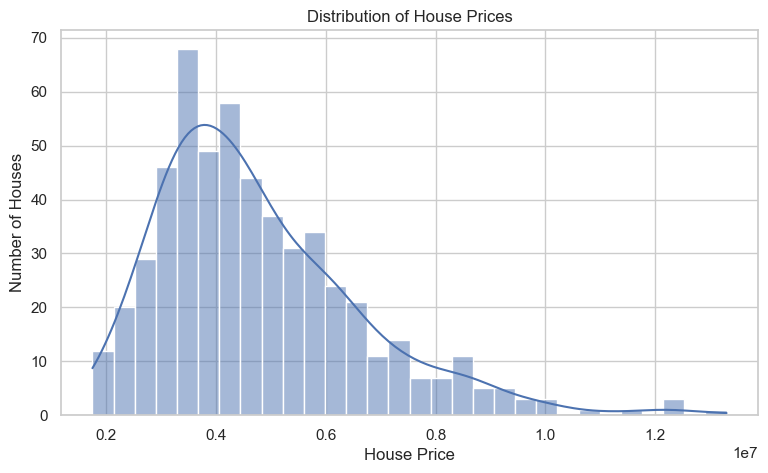

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(df['price'], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.show()

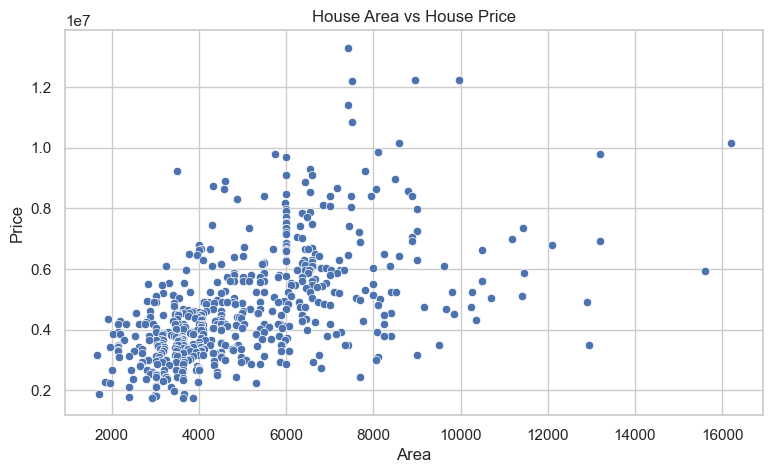

In [9]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='area',
    y='price'
)

plt.title("House Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")

plt.show()

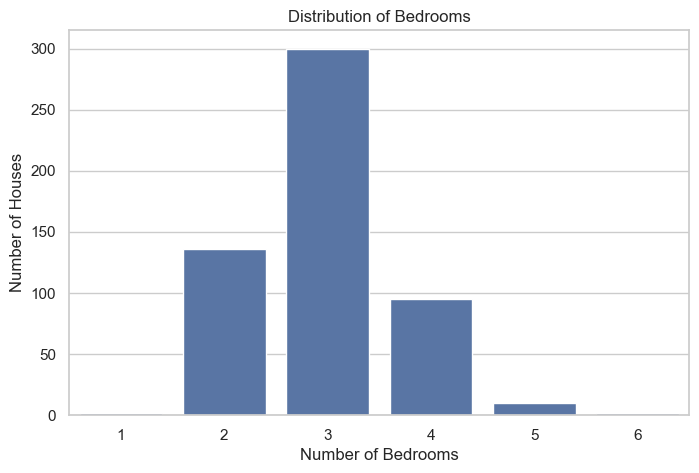

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='bedrooms'
)

plt.title("Distribution of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Houses")

plt.show()

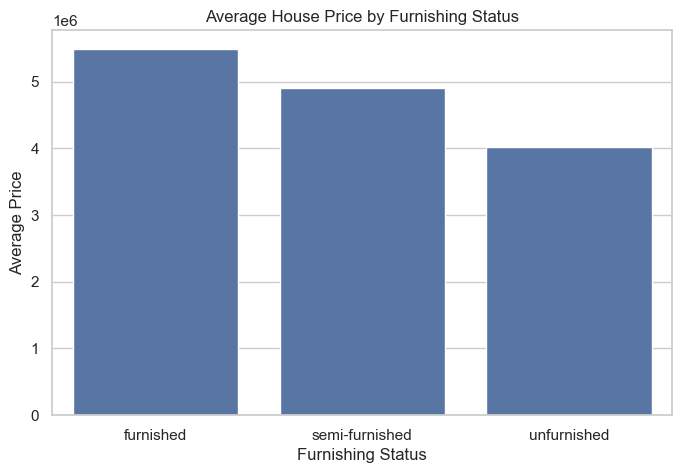

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='furnishingstatus',
    y='price',
    errorbar=None
)

plt.title("Average House Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Price")

plt.show()

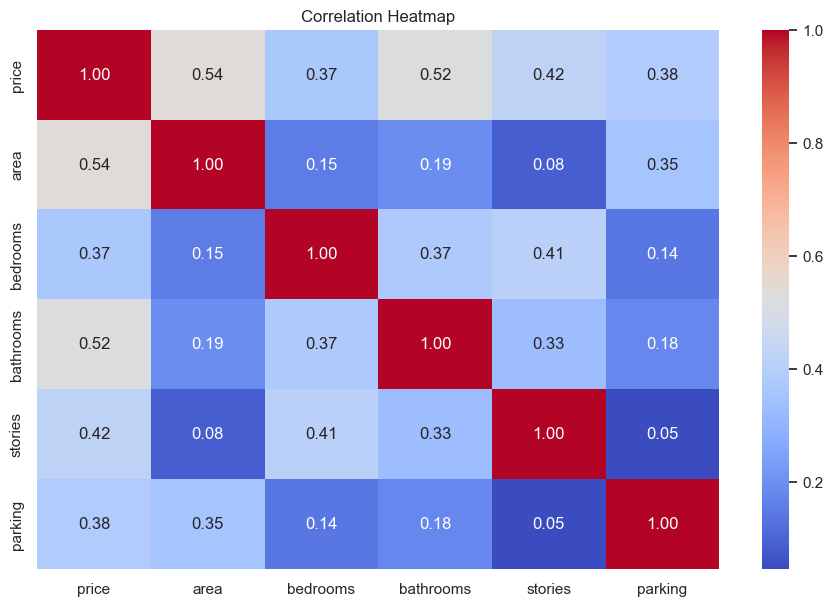

In [12]:
plt.figure(figsize=(11, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

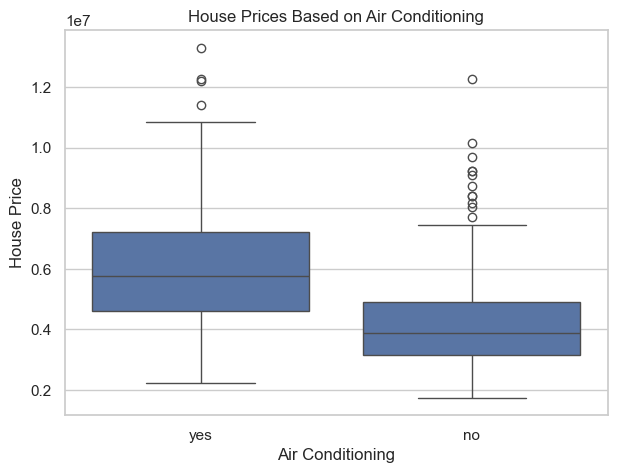

In [13]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='airconditioning',
    y='price'
)

plt.title("House Prices Based on Air Conditioning")
plt.xlabel("Air Conditioning")
plt.ylabel("House Price")

plt.show()

In [14]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['price'] < lower_limit) |
    (df['price'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("Number of potential outliers:", len(outliers))

display(outliers.head())

Lower limit: -35000.0
Upper limit: 9205000.0
Number of potential outliers: 15


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [15]:
# Correlation between area and price
area_corr = df['area'].corr(df['price'])

# Average prices based on furnishing status
furnishing_prices = df.groupby(
    'furnishingstatus'
)['price'].mean()

# Average prices based on air conditioning
ac_prices = df.groupby(
    'airconditioning'
)['price'].mean()

# Average prices based on preferred area
location_prices = df.groupby(
    'prefarea'
)['price'].mean()

print("========== DATASET INSIGHTS ==========")

print("\n1. Area and Price")
print("Correlation:", round(area_corr, 3))

print("\n2. Average Price by Furnishing Status")
print(furnishing_prices)

print("\n3. Average Price by Air Conditioning")
print(ac_prices)

print("\n4. Average Price by Preferred Area")
print(location_prices)

print("\n5. Most Common Furnishing Status")
print(df['furnishingstatus'].mode()[0])

print("\n6. Average House Price")
print(round(df['price'].mean(), 2))

========== DATASET INSIGHTS ==========

1. Area and Price
Correlation: 0.536

2. Average Price by Furnishing Status
furnishingstatus
furnished         5.495696e+06
semi-furnished    4.907524e+06
unfurnished       4.013831e+06
Name: price, dtype: float64

3. Average Price by Air Conditioning
airconditioning
no     4.191940e+06
yes    6.013221e+06
Name: price, dtype: float64

4. Average Price by Preferred Area
prefarea
no     4.425299e+06
yes    5.879046e+06
Name: price, dtype: float64

5. Most Common Furnishing Status
semi-furnished

6. Average House Price
4766729.25


In [17]:
print("""
========== CONCLUSION ==========

1. House area has a positive relationship with house price.

2. Furnishing status is associated with differences
   in average house prices.

3. Houses with air conditioning have a higher average
   price in this dataset.

4. Houses in preferred areas have a higher average
   price in this dataset.

5. Data cleaning and preprocessing help prepare
   the dataset for further analysis.

6. Visualizations help identify patterns and
   relationships between different features.

Overall, exploratory data analysis helps us understand
the factors associated with housing prices.
""")


========== CONCLUSION ==========

1. House area has a positive relationship with house price.

2. Furnishing status is associated with differences
   in average house prices.

3. Houses with air conditioning have a higher average
   price in this dataset.

4. Houses in preferred areas have a higher average
   price in this dataset.

5. Data cleaning and preprocessing help prepare
   the dataset for further analysis.

6. Visualizations help identify patterns and
   relationships between different features.

Overall, exploratory data analysis helps us understand
the factors associated with housing prices.



In [ ]:
df.to_csv("cleaned_housing_data.csv", index=False)

print("Cleaned dataset saved successfully!")